<a href="https://colab.research.google.com/github/buntyedutainer/allocation-optimizer/blob/main/Day05_Optimal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Greedy gave us a decent total, but it left the result partly to luck. Today we build a method that finds the assignment with the highest total happiness, and it does so without trying every possibility. Then we compare it with greedy on the same numbers.

Two ideas for today

Idea 1: turn places into seats. A project with 4 places becomes 4 identical seats. The problem is now a table with one row per student and one column per seat. We need to give every student one seat, with no seat used twice, so that the total score is as high as possible. A clever method called the Hungarian algorithm solves exactly this problem quickly. We don't need to know how it works inside, because scipy has it ready as linear_sum_assignment.

Idea 2: optimal for what? The method promises the best total score, and nothing else. It may still leave one student with a poor outcome, or choose among many assignments that tie. "Optimal" always means optimal for the number we told it to maximise, so choosing that number is a decision about values (Day 3's weights again).

In [1]:
# Cell 1: fetch your earlier files if this is a fresh session
import os, subprocess
if not os.path.exists("scores.csv"):
    subprocess.run(["git", "clone", "-q", "https://github.com/buntyedutainer/allocation-optimizer", "repo"])
    subprocess.run("cp repo/data/*.csv .", shell=True)
    subprocess.run("cp repo/src/*.py .", shell=True)
print([f for f in ["scores.csv", "projects.csv", "preferences.csv", "matching.py"] if os.path.exists(f)])

['scores.csv', 'projects.csv', 'preferences.csv', 'matching.py']


Add the optimal method to your tools file. The -a means "append". Run this cell once, because running it twice adds the functions twice.

In [2]:
%%writefile -a matching.py


def match_optimal(score, rank_table, capacity, listed_only=True, penalty=100.0):
    """The assignment with the highest total happiness (Hungarian method on a seat table)."""
    from scipy.optimize import linear_sum_assignment
    seats = [p for p in capacity.index for _ in range(int(capacity[p]))]      # one column per seat
    values = score[seats].values.astype(float)                                # students x seats
    if listed_only:
        unlisted = (rank_table[seats].values == UNLISTED_RANK)
        values = values - penalty * unlisted               # a heavy fine for unlisted projects, so they are used only if forced
    rows, cols = linear_sum_assignment(values, maximize=True)
    return pd.Series({score.index[r]: seats[c] for r, c in zip(rows, cols)})


def objective(assign, score, rank_table, listed_only=True, penalty=100.0):
    """What the optimal method maximises: total happiness, minus a fine for each unlisted placement."""
    total = sum(score.loc[s, p] for s, p in assign.items())
    if listed_only:
        total -= penalty * sum(rank_table.loc[s, p] == UNLISTED_RANK for s, p in assign.items())
    return total

Appending to matching.py


First, trust but verify. Does the method give the right answer on your Day 1 example, and does it agree with brute force on random small cases?

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import permutations
import time
import matching as M

# 1. Your Day 1 example. The best total was 27.
toy = pd.DataFrame([[9, 8, 3, 1], [9, 2, 1, 1], [8, 7, 6, 2], [7, 6, 5, 4]],
                   index=["Asha", "Ben", "Chitra", "Dev"], columns=["P1", "P2", "P3", "P4"])
toy_assign = M.match_optimal(toy, None, pd.Series(1, index=toy.columns), listed_only=False)
print("Day 1 example:", toy_assign.to_dict(), "| total:", M.objective(toy_assign, toy, None, listed_only=False))

# 2. Twenty random 6x6 cases: compare with trying every possibility
rng = np.random.default_rng(0)
agree = 0
for _ in range(20):
    s = pd.DataFrame(rng.integers(0, 11, size=(6, 6)).astype(float),
                     index=[f"S{i}" for i in range(6)], columns=[f"P{i}" for i in range(6)])
    best = max(sum(s.iloc[i, j] for i, j in enumerate(perm)) for perm in permutations(range(6)))
    got = M.objective(M.match_optimal(s, None, pd.Series(1, index=s.columns), listed_only=False), s, None, listed_only=False)
    agree += (best == got)
print(f"Agrees with brute force in {agree} of 20 random cases")

Day 1 example: {'Asha': 'P2', 'Ben': 'P1', 'Chitra': 'P3', 'Dev': 'P4'} | total: 27
Agrees with brute force in 20 of 20 random cases


In [4]:
score, projects, capacity, rank_table = M.load()

seats = [p for p in capacity.index for _ in range(int(capacity[p]))]
print("The first 8 seats:", seats[:8], "| total seats:", len(seats), "| students:", len(score))

opt = M.match_optimal(score, rank_table, capacity)
greedy = M.match_greedy(score, rank_table, capacity, list(score.index))     # the S01-first line-up from Day 4

print("Optimal:", M.validate(opt, score, capacity), "| Greedy:", M.validate(greedy, score, capacity))
table = pd.DataFrame({"Greedy (S01 first)": M.summary(M.outcomes(greedy, score, rank_table)),
                      "Optimal": M.summary(M.outcomes(opt, score, rank_table))}).T.round(1)
table

The first 8 seats: ['P01', 'P01', 'P01', 'P01', 'P02', 'P02', 'P02', 'P02'] | total seats: 44 | students: 40
Optimal: ['valid'] | Greedy: ['valid']


,average happiness,top-1 %,top-3 %,not on their list %,worst rank,lowest happiness
Greedy (S01 first),4.8,15.0,30.0,17.5,6.0,1.0
Optimal,5.9,25.0,45.0,7.5,6.0,1.5


The fair test. Is optimal better than greedy for every possible line-up? We use the same 200 line-ups as Day 4.

In [5]:
def run_many(fn, n=200, seed=0):
    rng = np.random.default_rng(seed)
    rows, counts, objs = [], [], []
    for _ in range(n):
        order = list(rng.permutation(score.index))
        a = fn(order)
        out = M.outcomes(a, score, rank_table)
        rows.append(M.summary(out))
        counts.append(np.bincount(out["rank"], minlength=7)[1:])        # how many students got rank 1..6
        objs.append(M.objective(a, score, rank_table))
    return pd.DataFrame(rows), np.array(counts), np.array(objs)

g_rows, g_counts, g_objs = run_many(lambda o: M.match_greedy(score, rank_table, capacity, o))
opt_obj = M.objective(opt, score, rank_table)

print(f"Optimal objective: {opt_obj:.1f}")
print(f"Greedy objective over 200 line-ups: lowest {g_objs.min():.1f} | average {g_objs.mean():.1f} | highest {g_objs.max():.1f}")
print(f"Line-ups where optimal is at least as good as greedy: {(opt_obj >= g_objs - 1e-9).sum()} of 200")
print(f"Line-ups where greedy reaches the optimal total:      {(abs(g_objs - opt_obj) < 1e-9).sum()} of 200")

Optimal objective: -64.1
Greedy objective over 200 line-ups: lowest -1022.5 | average -634.4 | highest -283.6
Line-ups where optimal is at least as good as greedy: 200 of 200
Line-ups where greedy reaches the optimal total:      0 of 200


Does the order of the students matter to the optimal method?

In [6]:
rng = np.random.default_rng(5)
objs, changed = [], []
for _ in range(20):
    order = list(rng.permutation(score.index))
    a = M.match_optimal(score.loc[order], rank_table.loc[order], capacity)
    objs.append(M.objective(a, score, rank_table))
    changed.append(int((a.reindex(score.index) != opt.reindex(score.index)).sum()))

print("Objective across 20 shuffles: lowest", round(min(objs), 2), "| highest", round(max(objs), 2))
print("Students whose project differs from the first run (ties):", changed)

Objective across 20 shuffles: lowest -64.07 | highest -64.07
Students whose project differs from the first run (ties): [2, 2, 4, 8, 6, 2, 4, 2, 2, 6, 4, 4, 6, 4, 7, 6, 6, 2, 4, 6]


Who gets what? Compare the number of students at each rank.

            Greedy (average of 200)  Optimal
rank 1                          7.4       10
rank 2                          3.6        5
rank 3                          3.2        3
rank 4                         11.6       11
rank 5                          6.0        8
not listed                      8.3        3


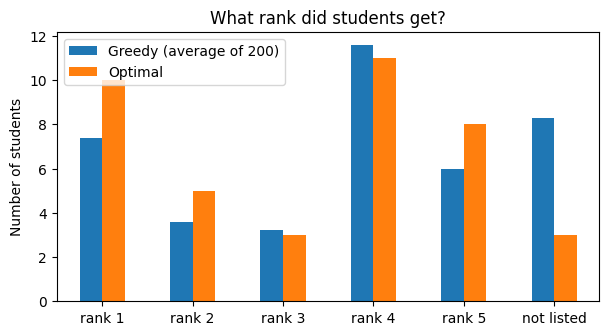

In [7]:
labels = ["rank 1", "rank 2", "rank 3", "rank 4", "rank 5", "not listed"]
opt_counts = np.bincount(M.outcomes(opt, score, rank_table)["rank"], minlength=7)[1:]
dist = pd.DataFrame({"Greedy (average of 200)": g_counts.mean(axis=0).round(1), "Optimal": opt_counts}, index=labels)
print(dist)

dist.plot(kind="bar", figsize=(7, 3.5))
plt.ylabel("Number of students")
plt.title("What rank did students get?")
plt.xticks(rotation=0)
plt.show()

How fast is it? Brute force was hopeless beyond a dozen students.

In [8]:
from scipy.optimize import linear_sum_assignment
rng = np.random.default_rng(0)
for n in [40, 200, 1000]:
    big = rng.random((n, n))
    t0 = time.time()
    linear_sum_assignment(big, maximize=True)
    print(f"{n:5d} students and {n:5d} seats: {time.time() - t0:.2f} seconds")

   40 students and    40 seats: 0.00 seconds
  200 students and   200 seats: 0.00 seconds
 1000 students and  1000 seats: 0.06 seconds


Save the results.

In [9]:
table.to_csv("optimal_vs_greedy_single.csv")
dist.to_csv("rank_distribution_day5.csv")
opt.rename("project").to_csv("assignment_optimal.csv")
print("Saved three CSV files")

Saved three CSV files
